# 02 Results

Loads `results/` only (no raw data) and draws the figures saved to `results/figures/`. Every number is from the held-out test set unless a cell says CV. The random and spatial splits have different test cells, so compare a model to itself across splits, and models to each other within a split.

## Summary

- **Baseline LR.** The `baseline_lr` row is least squares on raw counts of 3 POI types, trained on non-zero cells and untuned: the simplest reasonable model and the one this project started from. It is scored on the same test cells as every other model. On unseen blocks it reaches R² 0.62, Spearman 0.85 and top-10% hit rate 0.71, but predicts negative counts for 307 of 649 cells.
- **Only boosted trees clearly beat it on unseen blocks.** XGBoost: R² 0.70, Spearman 0.90, MAE 14% lower, Poisson deviance 44% lower. The top-10% hit rate is nearly unchanged (0.72 vs 0.71).
- **Boosting, not XGBoost, is what wins.** sklearn's HistGradientBoosting (`hgb`) with the same loss and budget reaches spatial R² 0.69 and the same MAE, with a lower top-10% hit rate (0.68).
- **The hurdle model** (P(any trips) x trips if any, same trees as `hgb`) lowers spatial MAE by 1% and deviance by 3% vs `hgb`, and cuts the median prediction on zero cells from 4 to 1. It does not fix supply gaps: those cells look busy to the classifier too.
- **More features and fancier models are not enough on their own.** The Poisson GLM (0.49) and the GCN (0.53) have lower spatial R² than Baseline LR. The ridge-on-log variant is the worst model on R² (-0.10), though its Spearman stays at 0.88. Duan's smearing correction was tried and made it worse (random R² -5.6).
- **A random split flatters every model with positive R²:** R² drops by 0.10 (XGBoost, Baseline LR) to 0.28 (Poisson GLM) on unseen blocks. Every model loses top-10% hit rate (0.07 to 0.27).
- **The features-free spatial kNN shows the leak most clearly:** best random-split Spearman (0.91), worst spatial one (0.78).
- **Easy zeros do not drive the headline.** Dropping trivial cells moves R² by at most 0.03 for every model except ridge (0.06). It lowers the top-10% hit rate by 0.02 to 0.11.
- **The worst errors are supply gaps.** Two held-out blocks near 22.74N, 114.05E average about 340 POIs per cell yet have about 460 trips in total. The three tree models predict 126k to 134k.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from biketrips import config, evaluate, plots

cfg = config.load_config()
res = cfg["data"]["results_dir"]
fig_dir = res / "figures"
order = ["baseline_lr", "linear", "knn", "poisson", "xgb", "hgb", "hurdle", "gcn"]
preds = pd.read_csv(res / "predictions.csv")
pd.set_option("display.precision", 3)

## Test scores, random vs spatial split

In [2]:
main = ["mae", "rmse", "poisson_deviance", "spearman", "top10_hit", "r2", "n_clipped"]
table = evaluate.test_table(res / "metrics.csv", main).reindex(order, level="model")
table

metric                       mae       rmse  poisson_deviance  spearman  \
model       split_type                                                    
baseline_lr random      1840.788   4386.705          2835.480     0.798   
            spatial     2536.509   5929.769          4081.412     0.848   
linear      random      2591.475  10051.896          4034.140     0.892   
            spatial     3355.593  10112.081          5580.551     0.882   
knn         random      1937.195   5235.527          2089.206     0.914   
            spatial     3723.104   7728.891          5719.142     0.777   
poisson     random      1542.947   4001.118          1533.039     0.871   
            spatial     2732.529   6858.091          2875.776     0.879   
xgb         random      1409.140   3683.006          1310.870     0.900   
            spatial     2182.033   5255.692          2271.930     0.896   
hgb         random      1459.729   3734.278          1323.108     0.902   
            spatial     2182.379   5368.514          2424.930     0.895   
hurdle      random      1479.097   3764.535          1349.688     0.910   
            spatial     2154.140   5331.919          2353.724     0.900   
gcn         random      1615.043   4309.455          1636.325     0.897   
            spatial     2734.191   6630.117          3726.904     0.886   

metric                  top10_hit     r2  n_clipped  
model       split_type                               
baseline_lr random          0.773  0.720      349.0  
            spatial         0.708  0.620      307.0  
linear      random          0.803 -0.471      121.0  
            spatial         0.615 -0.104       83.0  
knn         random          0.758  0.601        0.0  
            spatial         0.492  0.355        0.0  
poisson     random          0.818  0.767        0.0  
            spatial         0.692  0.492        0.0  
xgb         random          0.848  0.803        0.0  
            spatial         0.723  0.702        0.0  
hgb         random          0.818  0.797        0.0  
            spatial         0.677  0.689        0.0  
hurdle      random          0.818  0.794        0.0  
            spatial         0.692  0.693        0.0  
gcn         random          0.788  0.730        0.0  
            spatial         0.646  0.525        0.0

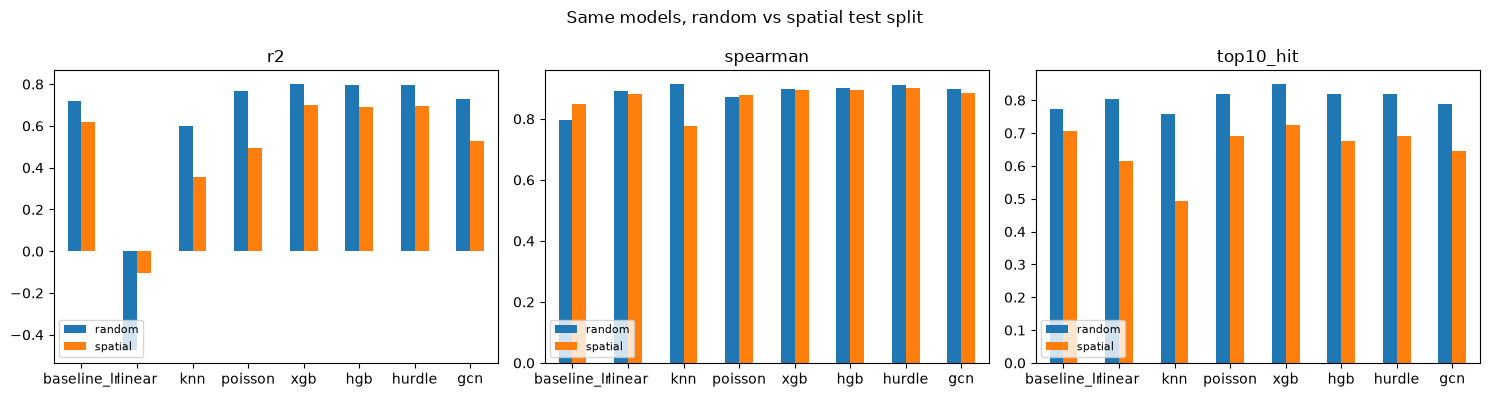

In [3]:
axes = plots.split_comparison(table, ["r2", "spearman", "top10_hit"])
plt.suptitle("Same models, random vs spatial test split")
plt.tight_layout()
plt.savefig(fig_dir / "random_vs_spatial.png", dpi=120)

## The leak, in one column

Drop from random to spatial split for each model. Positive means the random split scored higher. The kNN baseline uses only location, so its drop is the size of the spatial leak.

In [4]:
(table.xs("random", level="split_type") - table.xs("spatial", level="split_type"))[["r2", "spearman", "top10_hit"]].reindex(order)

metric,r2,spearman,top10_hit
model,,,
baseline_lr,0.099,-0.050,0.065
linear,-0.367,0.010,0.188
knn,0.246,0.137,0.265
poisson,0.275,-0.008,0.126
xgb,0.101,0.004,0.125
hgb,0.108,0.008,0.141
hurdle,0.101,0.010,0.126
gcn,0.204,0.010,0.142


## With and without trivial cells

Trivial cells have zero POIs and zero or unknown population (water, mountains, border strip). They are easy zeros. Scores without them show whether easy zeros inflate the headline.

In [5]:
both = ["r2", "r2_nontrivial", "spearman", "spearman_nontrivial", "top10_hit", "top10_hit_nontrivial"]
evaluate.test_table(res / "metrics.csv", both).reindex(order, level="model")

metric                     r2  r2_nontrivial  spearman  spearman_nontrivial  \
model       split_type                                                        
baseline_lr random      0.720          0.711     0.798                0.793   
            spatial     0.620          0.601     0.848                0.829   
linear      random     -0.471         -0.519     0.892                0.893   
            spatial    -0.104         -0.162     0.882                0.864   
knn         random      0.601          0.588     0.914                0.921   
            spatial     0.355          0.357     0.777                0.814   
poisson     random      0.767          0.759     0.871                0.878   
            spatial     0.492          0.466     0.879                0.867   
xgb         random      0.803          0.796     0.900                0.908   
            spatial     0.702          0.686     0.896                0.882   
hgb         random      0.797          0.790     0.902                0.912   
            spatial     0.689          0.673     0.895                0.879   
hurdle      random      0.794          0.787     0.910                0.918   
            spatial     0.693          0.677     0.900                0.886   
gcn         random      0.730          0.721     0.897                0.902   
            spatial     0.525          0.501     0.886                0.868   

metric                  top10_hit  top10_hit_nontrivial  
model       split_type                                   
baseline_lr random          0.773                 0.727  
            spatial         0.708                 0.685  
linear      random          0.803                 0.691  
            spatial         0.615                 0.574  
knn         random          0.758                 0.673  
            spatial         0.492                 0.463  
poisson     random          0.818                 0.745  
            spatial         0.692                 0.630  
xgb         random          0.848                 0.782  
            spatial         0.723                 0.685  
hgb         random          0.818                 0.782  
            spatial         0.677                 0.685  
hurdle      random          0.818                 0.764  
            spatial         0.692                 0.667  
gcn         random          0.788                 0.745  
            spatial         0.646                 0.630

## Inner CV vs test (spatial)

Mean over the 5 inner folds for the chosen hyperparameters, next to the single held-out test score.

In [6]:
m = evaluate.latest(res / "metrics.csv")
m = m[(m["split_type"] == "spatial") & m["metric"].isin(["r2", "spearman", "top10_hit"])]
m.assign(set=m["fold"].where(m["fold"] == "test", "cv_mean")).pivot_table(
    index="model", columns=["metric", "set"], values="value").reindex(order)

metric           r2        spearman        top10_hit       
set         cv_mean   test  cv_mean   test   cv_mean   test
model                                                      
baseline_lr   0.670  0.620    0.784  0.848     0.694  0.708
linear       -0.276 -0.104    0.869  0.882     0.704  0.615
knn           0.155  0.355    0.685  0.777     0.393  0.492
poisson       0.722  0.492    0.847  0.879     0.736  0.692
xgb           0.717  0.702    0.880  0.896     0.745  0.723
hgb           0.720  0.689    0.883  0.895     0.750  0.677
hurdle        0.727  0.693    0.881  0.900     0.747  0.692
gcn           0.639  0.525    0.869  0.886     0.718  0.646

## Top-k hit rate

If a planner can place stations in the top k% of cells, how many of the true top k% does each model find?

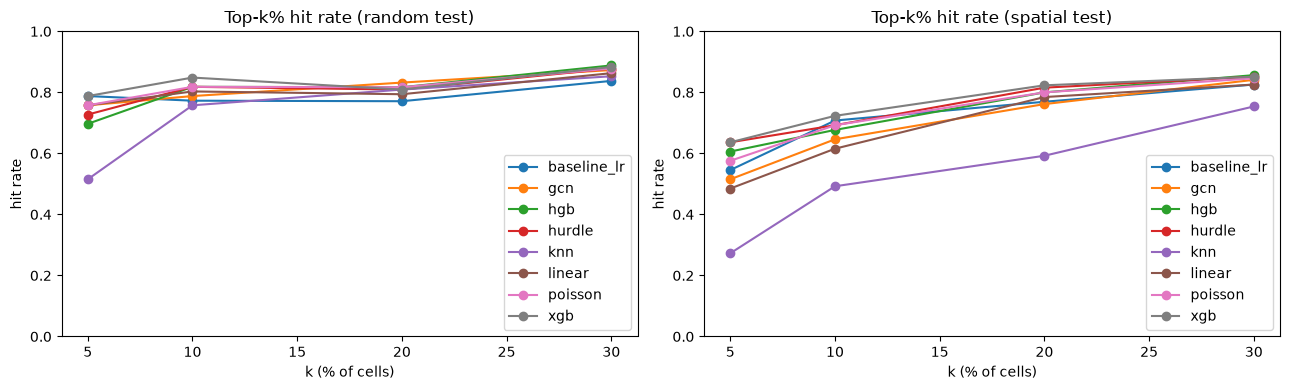

In [7]:
curve = evaluate.hit_curve(preds, [0.05, 0.1, 0.2, 0.3])
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
plots.hit_curve(curve, ax[0], "random")
plots.hit_curve(curve, ax[1], "spatial")
ax[0].set_ylim(0, 1); ax[1].set_ylim(0, 1)
plt.tight_layout()
plt.savefig(fig_dir / "topk_hit_rate.png", dpi=120)

## Residual maps (spatial test cells)

Held-out blocks show where each model fails. Red means over-predicted.

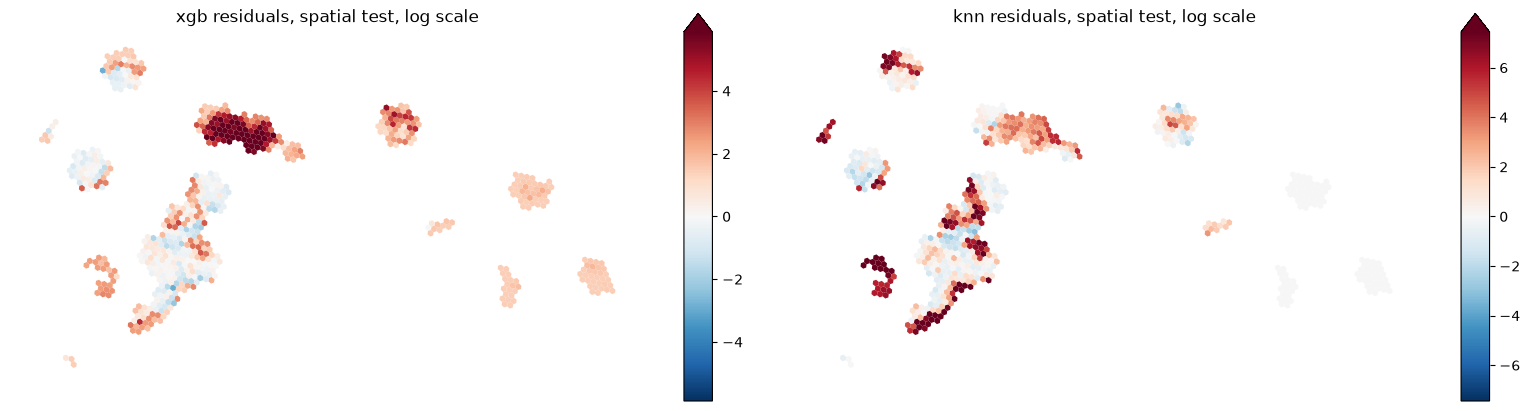

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
plots.residual_map(preds, "xgb", "spatial", ax[0])
plots.residual_map(preds, "knn", "spatial", ax[1])
plt.tight_layout()
plt.savefig(fig_dir / "residual_map.png", dpi=120)

## Feature importance (XGBoost, spatial split)

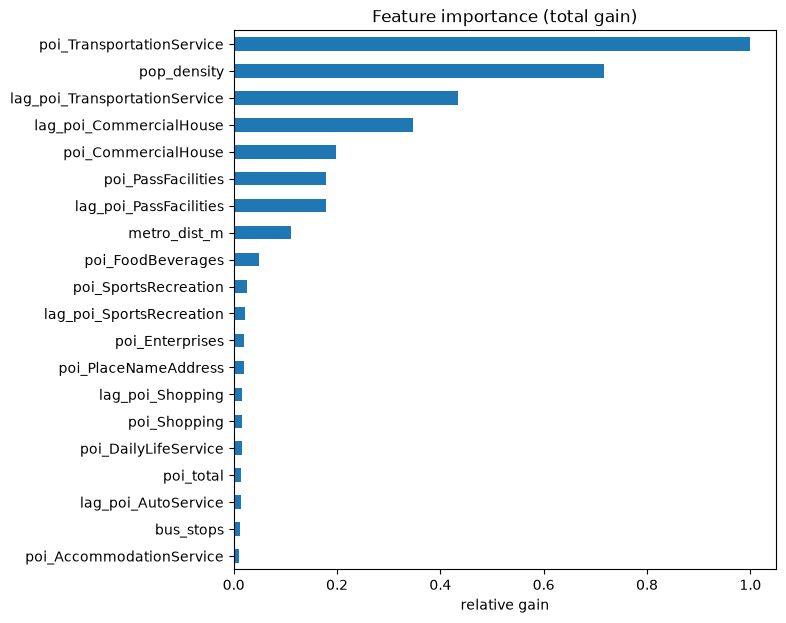

In [9]:
imp = pd.read_csv(res / "xgb_importance.csv", index_col="feature")["total_gain"]
plots.importance(imp);  # saved as figures/xgb_importance.png by run_experiments.py

## Chosen hyperparameters

In [10]:
print(yaml.safe_dump(yaml.safe_load((res / "best_params.yaml").read_text()), sort_keys=False))

linear:
  random:
    alpha: 100.0
  spatial:
    alpha: 0.001
knn:
  random:
    k: 3
  spatial:
    k: 20
poisson:
  random:
    alpha: 10.0
  spatial:
    alpha: 1.0
xgb:
  random:
    n_estimators: 437
    max_depth: 3
    learning_rate: 0.10121644277594667
    min_child_weight: 2
    subsample: 0.7991341332960198
    colsample_bytree: 0.5797511266530957
    reg_lambda: 0.5195693495666391
  spatial:
    n_estimators: 280
    max_depth: 3
    learning_rate: 0.06697564702803946
    min_child_weight: 6
    subsample: 0.7781664064121103
    colsample_bytree: 0.5815924087231175
    reg_lambda: 6.729109439459797
gcn:
  random:
    dropout: 0.3
    hidden: 16
    k: 4
    lr: 0.003
    max_epochs: 2000
    patience: 100
    val_frac: 0.2
  spatial:
    dropout: 0.3
    hidden: 16
    k: 4
    lr: 0.003
    max_epochs: 2000
    patience: 100
    val_frac: 0.2
baseline_lr:
  random:
    nonzero_only: true
  spatial:
    nonzero_only: true
hgb:
  random:
    max_iter: 412
    max_depth: 6
  